In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

from astropy import units as u
from astropy import constants as const

import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interact, FloatSlider, IntSlider

from pathlib import Path
import sys

# Use this checkout when running from the repository root or example/.
for root in (Path.cwd(), Path.cwd().parent):
    if (root / "src" / "redwine" / "kernels.py").is_file():
        sys.path.insert(0, str(root / "src"))
        break

from redwine.experimental.kernels import Wind, line as line_profile

In [2]:
E0 = 7. # keV

N0 = 1 # rest frame flux per unit solid angle

# Normalized emission line profile
N0 = 1 / (4*np.pi)

Emin = 5. # keV
Emax = 10. # keV
dE = 0.001 # keV
energies = np.arange(Emin, Emax+dE, dE)

is_photonflux = True

interactive(children=(FloatSlider(value=0.1, description='β₀', max=0.3, step=0.01), FloatSlider(value=0.03, de…

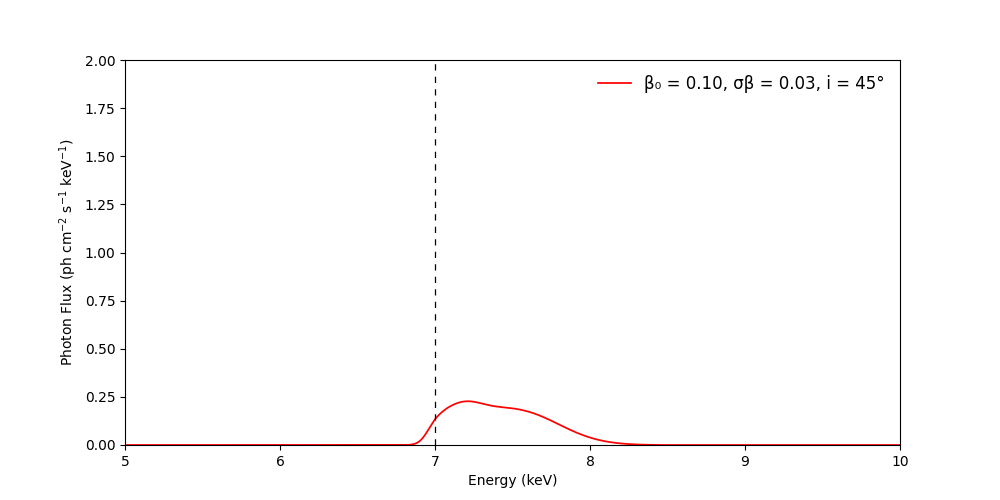

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
line, = ax.plot([], [], color='red', lw=1.25)
ax.set_xlabel('Energy (keV)')
ax.set_ylabel('Photon Flux (ph cm$^{-2}$ s$^{-1}$ keV$^{-1}$)')
ax.axvline(x=E0, color='black', lw=0.9, dashes=(5, 5))
ax.set_xlim(Emin, Emax)
ax.set_ylim(0., 2.)

# Keep the same energy centers and plot bin-averaged photon density.
edges = np.r_[energies - dE/2, energies[-1] + dE/2]

def plot_spectrum(beta, sigma, incl, thetain, thetaout, bicone):
    try:
        wind = Wind("gaussian", beta, sigma, thetain, thetaout, incl,
                    bicone=bool(bicone))
    except ValueError as exc:
        line.set_data([], [])
        if ax.get_legend() is not None:
            ax.get_legend().remove()
        ax.set_title(str(exc))
    else:
        y = (4*np.pi*N0) * line_profile(edges, E0, wind) / np.diff(edges)
        line.set_data(energies, y)
        ax.set_title("")
        ax.legend([f'β₀ = {beta:.2f}, σβ = {sigma:.2f}, i = {incl:.0f}°'],
                  loc='best', framealpha=0, prop={'weight':'normal', 'size':12})
    plt.draw()

beta_slider = FloatSlider(value=0.1, min=0, max=0.3, step=0.01, description='β₀')
sigma_slider = FloatSlider(value=0.03, min=0, max=0.1, step=0.005, description='σβ')
i_slider = FloatSlider(value=45, min=0, max=90, step=1, description='i (deg)')
thetain_slider = FloatSlider(value=20, min=0, max=90, step=1, description='θin (deg)')
thetaout_slider = FloatSlider(value=50, min=0, max=90, step=1, description='θout (deg)')
bicone_slider = IntSlider(value=0, min=0, max=1, description='Bicone')

interact(plot_spectrum, beta=beta_slider, sigma=sigma_slider, incl=i_slider,
         thetain=thetain_slider, thetaout=thetaout_slider, bicone=bicone_slider)

plt.show()
